## Step 1: Problem Framing & Theory Notes


1. What is Customer Churn? Why is it important?
- Customer churn means a customer stops using a company's services.
- Jio and Airtel predict churn to find customers who may leave and offer them better plans or discounts.
2. Confusion Matrix (TP, TN, FP, FN)
- TP (True Positive): Correctly predicts that a customer will leave.
- TN (True Negative): Correctly predicts that a customer will stay.
- FP (False Positive): Predicts a customer will leave, but they stay. The company may waste money on discounts.
- FN (False Negative): Predicts a customer will stay, but they leave. The company loses that customer and their future revenue.
3. What is Class Imbalance? How does SMOTE help?
- Class imbalance means one class has more data than another.
- Yes, the Telco Churn dataset is imbalanced: about 73% customers stay and 27% leave.
- SMOTE creates new artificial examples of the smaller class (churners).
- It helps the model learn better about customers who may leave. Apply it only to training data.
4. How do the four algorithms work?
KNN (K-Nearest Neighbors)
- Finds the K most similar customers.
- Predicts churn based on the majority class of those customers.
Naive Bayes
- Calculates the probability that a customer will leave or stay.
- It uses probabilities and assumes features are independent given the class.
SVM (Support Vector Machine)
- Finds a boundary between customers who leave and stay.
- It tries to keep the largest possible gap between the two groups.
Decision Tree
- Makes decisions using simple questions about customer data.
- It predicts whether a customer will leave or stay.
5. When would you choose Precision over Recall?
- I would choose Precision when discounts or special offers are expensive.
- High precision means most customers predicted to leave are actually likely to leave.
- This helps Jio or Airtel avoid wasting money on unnecessary offers.
- Recall is more important when the company wants to find as many customers likely to leave as possible.

##  Step 2: Dataset Loading & Exploratory Data Analysis


### 2.1  Load & Inspect

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\Ibhrahim ansari\Desktop\final exam\WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [3]:
df.shape

(7043, 21)

In [4]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
missing_summary = df.isna().sum()[df.isna().sum()>0]
print("There are not missing values:", missing_summary)

There are not missing values: Series([], dtype: int64)


In [7]:
duplicate_val = df.duplicated().sum()
print("There are not duplicates:", duplicate_val)

There are not duplicates: 0


In [8]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [9]:
df["TotalCharges"].isna().sum()

np.int64(11)

In [10]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

### 2.2  Univariate Analysis


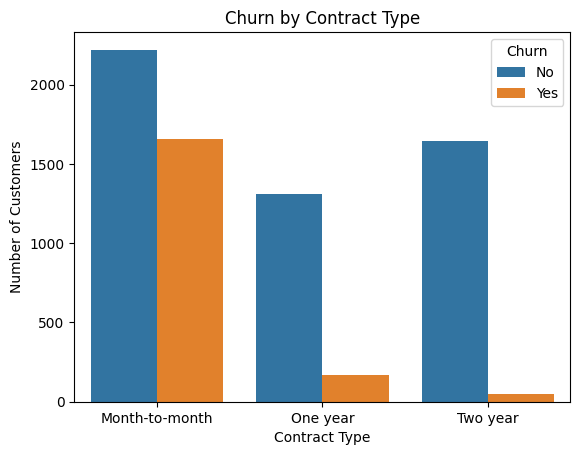

In [11]:
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.show()

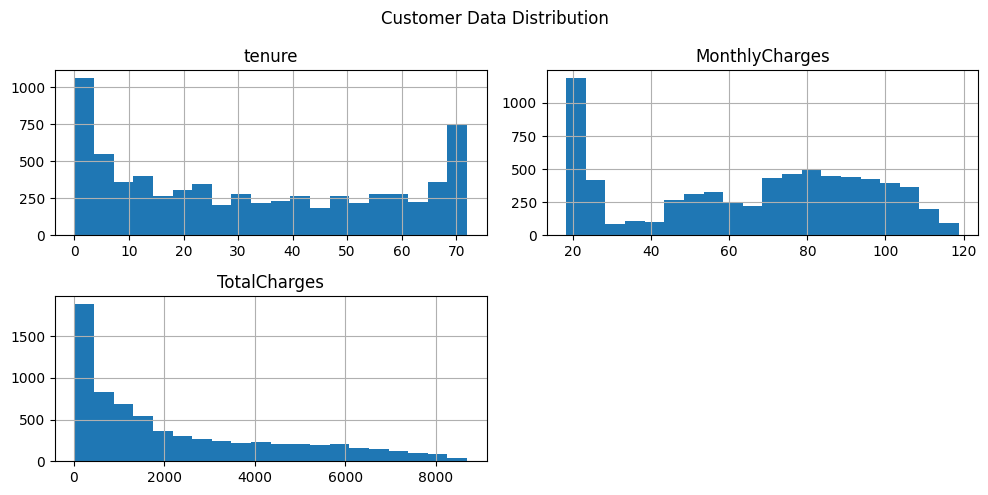

In [12]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].hist(figsize=(10, 5), bins=20)

plt.suptitle("Customer Data Distribution")
plt.tight_layout()
plt.show()

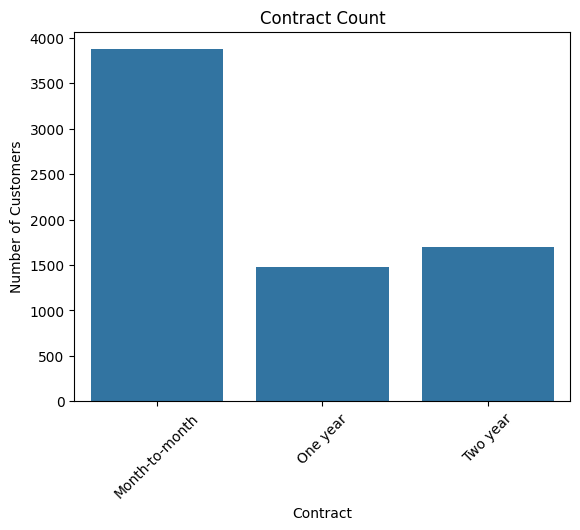

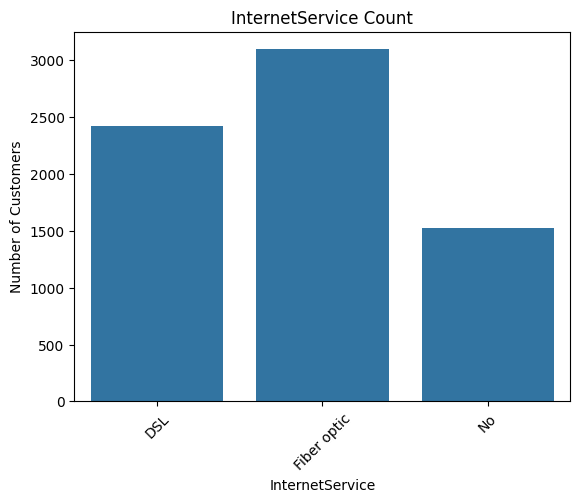

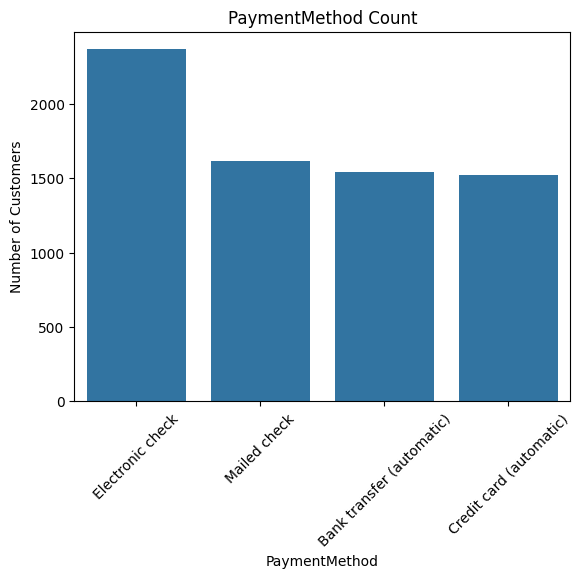

In [13]:
for col in ["Contract", "InternetService", "PaymentMethod"]:
    sns.countplot(data=df, x=col)
    plt.title(f"{col} Count")
    plt.xlabel(col)
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=45)
    plt.show()

### 2.3  Bivariate Analysis

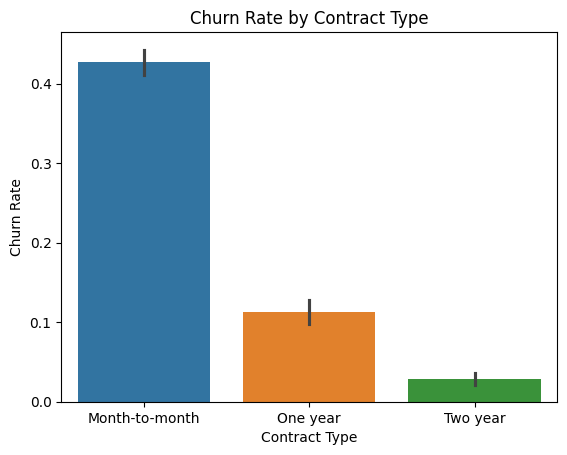

In [14]:
sns.barplot(data=df, x="Contract", y=(df["Churn"] == "Yes"), hue="Contract")
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate")
plt.show()

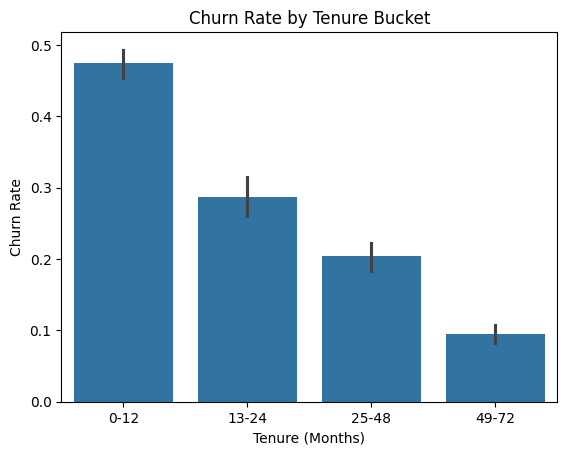

In [15]:
df["TenureBucket"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                            labels=["0-12", "13-24", "25-48", "49-72"])

sns.barplot(data=df, x="TenureBucket", y=(df["Churn"] == "Yes"))
plt.title("Churn Rate by Tenure Bucket")
plt.xlabel("Tenure (Months)")
plt.ylabel("Churn Rate")
plt.show()

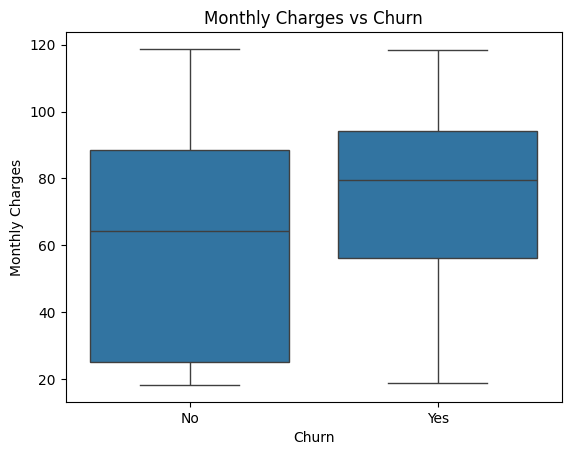

In [16]:
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()


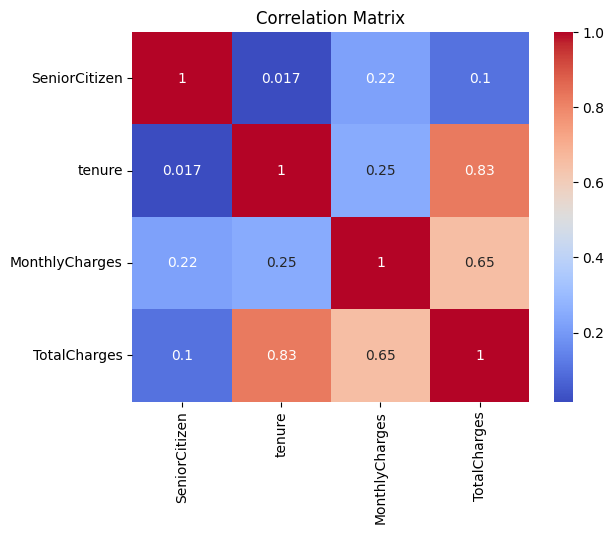

In [17]:
sns.heatmap(df.select_dtypes("number").corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

## Step 3: Data Preprocessing & Feature Engineering


### 3.1  Drop & Clean

In [18]:
df.drop(columns="customerID", axis=1)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureBucket
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0-12
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,25-48
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0-12
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,25-48
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0-12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,...,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No,13-24
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,...,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No,49-72
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No,0-12
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes,0-12


In [19]:
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

In [20]:
df["TotalCharges"].isna().sum()

np.int64(0)

### 3.2  Feature Engineering

In [21]:
df["tenure_group"] = pd.cut(df["tenure"],
                           bins=[-1, 12, 36, 60, 100],
                           labels=["New", "Mid", "Senior", "Loyal"])

In [22]:
services = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
            "TechSupport", "StreamingTV", "StreamingMovies"]

df["num_services"] = (df[services] == "Yes").sum(axis=1)

In [23]:
df["AutoPay"] = df["PaymentMethod"].str.contains("automatic", case=False).astype(int)

### 3.3  Encoding

In [24]:
cols = ["Partner", "Dependents", "PhoneService", "PaperlessBilling", "Churn"]
df[cols] = df[cols].replace({
    "Yes":1,
    "No":0
})

C:\Users\Ibhrahim ansari\AppData\Local\Temp\ipykernel_14776\1808268681.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[cols] = df[cols].replace({


In [25]:
from sklearn.preprocessing import OneHotEncoder
oe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
encoded = oe.fit_transform(df[["InternetService", "Contract", "PaymentMethod"]])
encoded_df = pd.DataFrame(encoded, columns=oe.get_feature_names_out())
df = df.drop(["InternetService", "Contract", "PaymentMethod"], axis=1)
df = pd.concat([df.reset_index(drop=True), encoded_df], axis=1)

In [26]:
df["tenure_group"] = df["tenure_group"].map({
    "New": 0, "Mid": 1, "Senior": 2, "Loyal": 3
})

# df = df.drop(["tenure"], axis=1)

### 3.4  Scaling

In [27]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
cols = ["tenure", "MonthlyCharges", "TotalCharges", "num_services"]

df[cols] = scaler.fit_transform(df[cols])

In [28]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
cols = ["tenure", "MonthlyCharges", "TotalCharges", "num_services"]

df[cols] = scaler.fit_transform(df[cols])

In [29]:
from sklearn.preprocessing import StandardScaler

cols = df.select_dtypes(include="number").columns.drop("Churn")

scaler = StandardScaler()
df[cols] = scaler.fit_transform(df[cols])

### 3.5  Handle Class Imbalance

In [32]:
df = df.drop("customerID", axis=1, errors="ignore")
df = pd.get_dummies(df, dtype=int)

X = df.drop("Churn", axis=1)
y = df["Churn"]

In [33]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

X = df.drop("Churn", axis=1)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Before SMOTE:\n", y_train.value_counts())

smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)

print("After SMOTE:\n", y_train.value_counts())



Before SMOTE:
 Churn
0    4139
1    1495
Name: count, dtype: int64
After SMOTE:
 Churn
0    4139
1    4139
Name: count, dtype: int64


In [55]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

X = df.drop("Churn", axis=1)
y = df["Churn"]

X_train_original, X_test, y_train_original, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train_smote, y_train_smote = SMOTE(random_state=42).fit_resample(
    X_train_original, y_train_original
)

### 3.6  Train-Test Split

In [56]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", y_test.shape)


X_train shape: (8278, 51)
X_test shape: (1409, 51)
y_train shape: (8278,)
X_test shape: (1409,)


##  Step 4: Model Building — KNN & Naive Bayes

In [57]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("AUC-ROC:", roc_auc_score(y_test, y_prob))

Accuracy: 0.7154009936124911
Precision: 0.47347740667976423
Recall: 0.6443850267379679
F1 Score: 0.5458663646659117
AUC-ROC: 0.7676095998346638


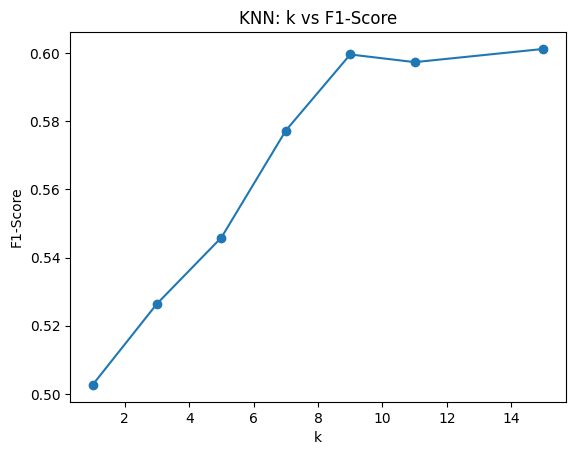

Best k: 15


In [58]:
from sklearn.metrics import f1_score

scores = []

for k in [1, 3, 5, 7, 9, 11, 15]:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    scores.append(f1_score(y_test, pred))

plt.plot([1, 3, 5, 7, 9, 11, 15], scores, marker="o")
plt.title("KNN: k vs F1-Score")
plt.xlabel("k")
plt.ylabel("F1-Score")
plt.show()

print("Best k:", [1, 3, 5, 7, 9, 11, 15][scores.index(max(scores))])

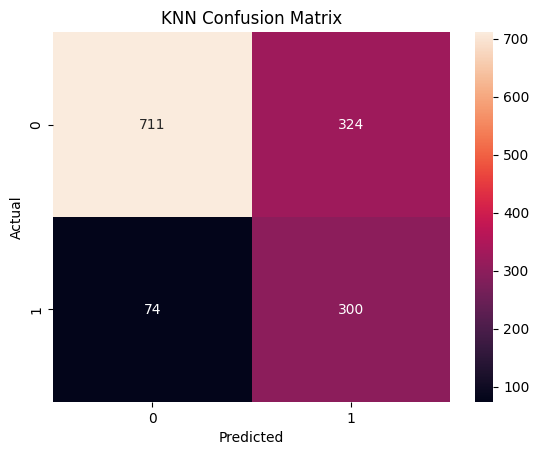

In [59]:
from sklearn.metrics import confusion_matrix

best_k = [1, 3, 5, 7, 9, 11, 15][scores.index(max(scores))]

model = KNeighborsClassifier(n_neighbors=best_k)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d")
plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

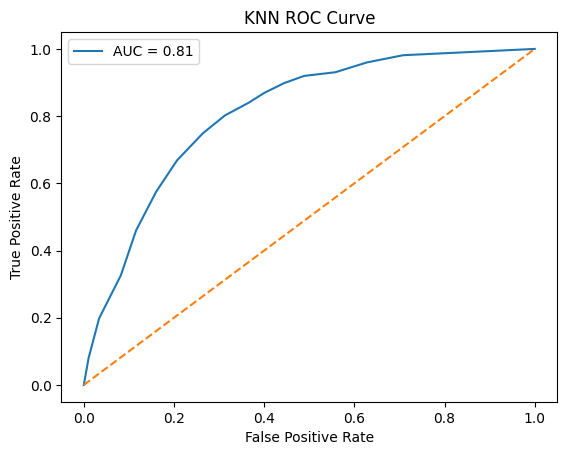

In [60]:
from sklearn.metrics import roc_curve, roc_auc_score

y_prob = model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_prob):.2f}")
plt.plot([0, 1], [0, 1], "--")
plt.title("KNN ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

## Naive Bayes — Gaussian NB


In [61]:
from sklearn.naive_bayes import GaussianNB
model = GaussianNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("AUC-ROC:", roc_auc_score(y_test, y_prob))
print("Class Prior:", model.class_prior_)

Accuracy: 0.7146912704045423
Precision: 0.4778481012658228
Recall: 0.8074866310160428
F1 Score: 0.6003976143141153
AUC-ROC: 0.819969516133199
Class Prior: [0.5 0.5]


## Step 5: Model Building — SVM & Decision Tree


Accuracy: 0.7778566359119943
Precision: 0.5764411027568922
Recall: 0.6149732620320856
F1: 0.5950840879689522
AUC-ROC: 0.8189284145805884


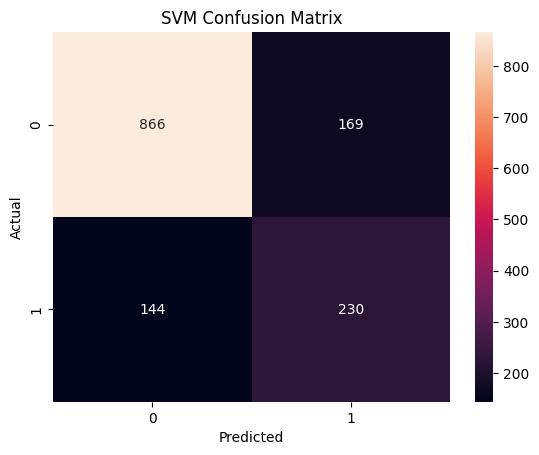

In [62]:
from sklearn.svm import SVC
model = SVC(kernel="rbf", C=1, gamma="scale", probability=True, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("AUC-ROC:", roc_auc_score(y_test, y_prob))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d")
plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### 5.2  Decision Tree Classifier


In [63]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

model = DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.7622427253371186
Precision: 0.5408805031446541
Recall: 0.6898395721925134
F1 Score: 0.6063454759106933


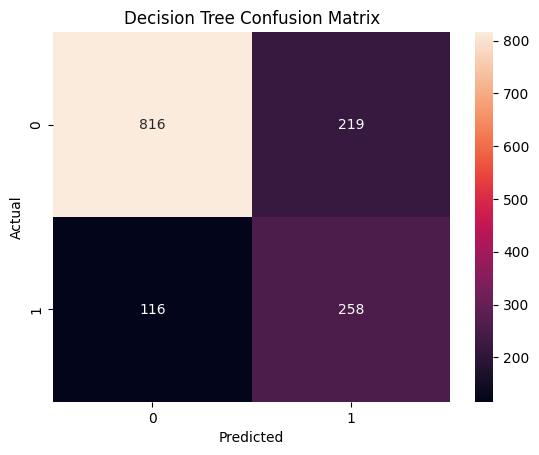

In [47]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d")
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

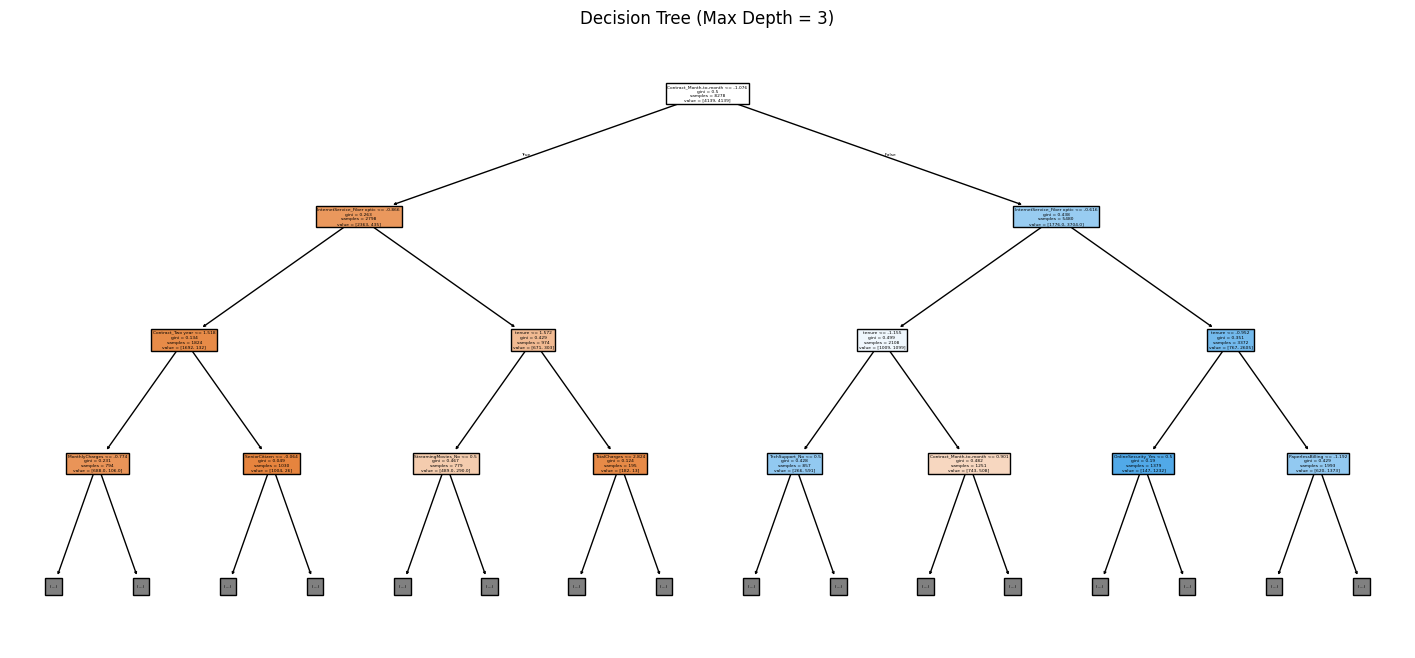

In [64]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 8))
plot_tree(model, max_depth=3, feature_names=X_train.columns, filled=True)
plt.title("Decision Tree (Max Depth = 3)")
plt.show()

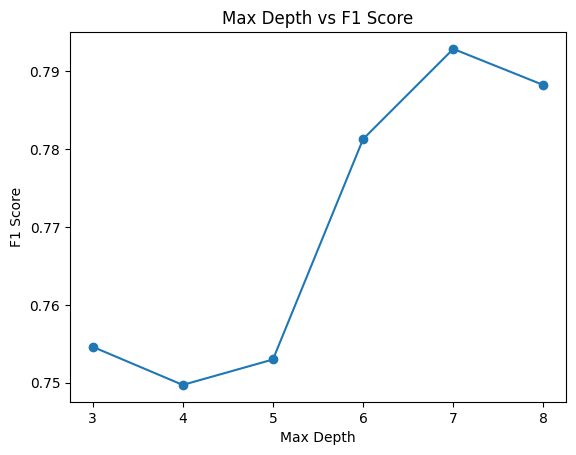

Best Depth: 7


In [65]:
from sklearn.model_selection import cross_val_score

depths = [3, 4, 5, 6, 7, 8]
scores = []

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, class_weight="balanced", random_state=42)
    score = cross_val_score(tree, X_train, y_train, cv=3, scoring="f1").mean()
    scores.append(score)

plt.plot(depths, scores, marker="o")
plt.title("Max Depth vs F1 Score")
plt.xlabel("Max Depth")
plt.ylabel("F1 Score")
plt.show()

best_depth = depths[scores.index(max(scores))]
print("Best Depth:", best_depth)

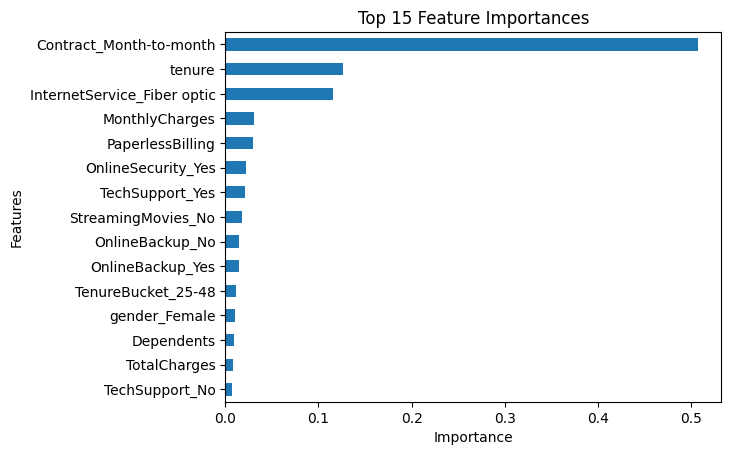

In [50]:
model = DecisionTreeClassifier(max_depth=best_depth, class_weight="balanced", random_state=42)
model.fit(X_train, y_train)

importance = pd.Series(model.feature_importances_, index=X_train.columns)
importance.nlargest(15).sort_values().plot(kind="barh")

plt.title("Top 15 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()

### 5.3  One Model with class_weight='balanced' vs SMOTE

In [66]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import recall_score

# SMOTE data
model1 = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
model1.fit(X_train, y_train)
pred1 = model1.predict(X_test)
recall1 = recall_score(y_test, pred1)

# Original data with class_weight
model2 = DecisionTreeClassifier(max_depth=best_depth, class_weight="balanced", random_state=42)
model2.fit(X_train_original, y_train_original)
pred2 = model2.predict(X_test)
recall2 = recall_score(y_test, pred2)

print("SMOTE Recall:", recall1)
print("Class Weight Recall:", recall2)

SMOTE Recall: 0.7379679144385026
Class Weight Recall: 0.7593582887700535


SMOTE and class_weight='balanced' were compared using Recall.
The model with higher Recall performed better at identifying churn customers.

## Step 6: Model Evaluation & Comparison

In [69]:
import time

In [70]:
models = {
    "KNN": KNeighborsClassifier(n_neighbors=best_k),
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(kernel="rbf", probability=True, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=best_depth, class_weight="balanced", random_state=42)
}

results = []

for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start

    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    results.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred, zero_division=0),
        recall_score(y_test, pred, zero_division=0),
        f1_score(y_test, pred, zero_division=0),
        roc_auc_score(y_test, prob),
        round(train_time, 3)
    ])

comparison = pd.DataFrame(results, columns=[
    "Model", "Accuracy", "Precision", "Recall",
    "F1-Score", "AUC-ROC", "Training Time (sec)"
])

comparison

,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Training Time (sec)
0,KNN,0.717530,0.480769,0.802139,0.601202,0.809265,0.007
1,Naive Bayes,0.714691,0.477848,0.807487,0.600398,0.819970,0.011
2,SVM,0.777857,0.576441,0.614973,0.595084,0.818928,10.933
3,Decision Tree,0.741661,0.509225,0.737968,0.602620,0.816093,0.050


In [71]:
comparison.sort_values("Recall", ascending=False)

,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Training Time (sec)
1,Naive Bayes,0.714691,0.477848,0.807487,0.600398,0.819970,0.011
0,KNN,0.717530,0.480769,0.802139,0.601202,0.809265,0.007
3,Decision Tree,0.741661,0.509225,0.737968,0.602620,0.816093,0.050
2,SVM,0.777857,0.576441,0.614973,0.595084,0.818928,10.933


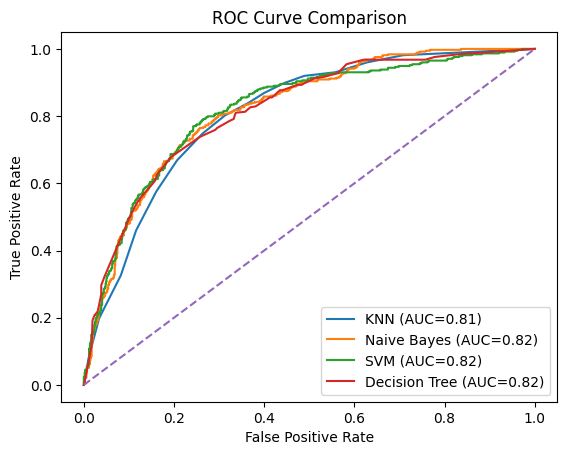

In [73]:
from sklearn.metrics import roc_curve, roc_auc_score


for name, model in models.items():
    prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, prob):.2f})")

plt.plot([0, 1], [0, 1], "--")
plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

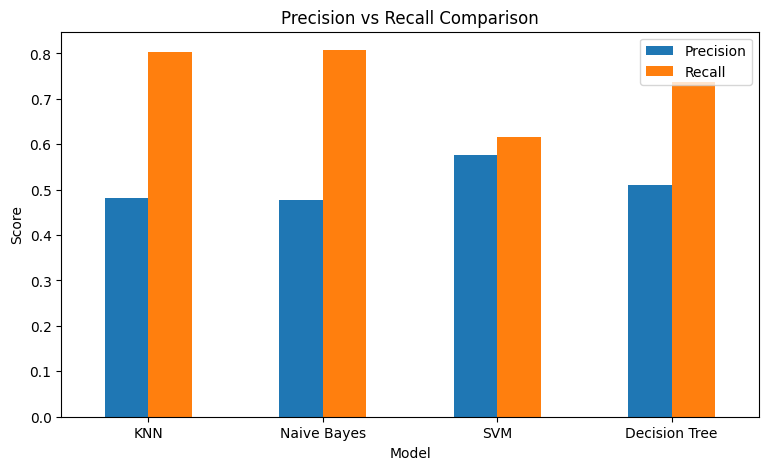

In [74]:
comparison.plot(
    x="Model",
    y=["Precision", "Recall"],
    kind="bar",
    figsize=(9, 5)
)

plt.title("Precision vs Recall Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend()
plt.show()

I recommend **Naive Bayes** because it has the highest Recall of 0.8075. It can identify more customers who may leave. Its training time is also very low at 0.011 seconds. However, its Precision is lower than SVM's, so some predictions may be wrong. Overall, Naive Bayes is a good choice because Recall is the most important metric for this project.

##  Step 7: Error Analysis & Interpretation

### 7.1  Error Analysis on Best Model

In [75]:
from sklearn.naive_bayes import GaussianNB

model = GaussianNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

fn = X_test[(y_test == 1) & (y_pred == 0)]

print("False Negatives:", len(fn))

False Negatives: 72


In [81]:
missed = df.loc[fn.index]

print("Average Tenure:", missed["tenure"].mean())
print("Average Monthly Charges:", missed["MonthlyCharges"].mean())


Average Tenure: 0.09064652519280966
Average Monthly Charges: 0.011174727540523812


False Negative customers are actual churners who were predicted as non-churners. We should compare their average tenure and MonthlyCharges with all churners. This helps us understand which types of customers the model fails to identify. Since the data is scaled, the values should be converted back to the original scale before making a final conclusion.

### 7.2  Feature Importance / Decision Insight


In [84]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    max_depth=best_depth,
    class_weight="balanced",
    random_state=42
)

tree_model.fit(X_train, y_train)

importance = pd.Series(
    tree_model.feature_importances_,
    index=X_train.columns
)

print(importance.sort_values(ascending=False).head(5))

Contract_Month-to-month        0.506853
tenure                         0.126705
InternetService_Fiber optic    0.115703
MonthlyCharges                 0.030823
PaperlessBilling               0.029804
dtype: float64


- Month-to-Month Contract: This is the most important feature for churn prediction, with an importance score of 0.507.
- Tenure: Customer tenure is important. The length of time a customer stays with the company helps predict churn.
- Fiber Optic Internet: Internet service type helps the model identify customers who may leave.
- Monthly Charges: Monthly bills help predict whether a customer may churn.
- Paperless Billing: Billing preference also contributes to churn prediction.
Conclusion: Contract type is the strongest feature in this Decision Tree model. These importance scores show how much each feature contributes to the model; they do not prove that a customer is a specific number of times more likely to churn.

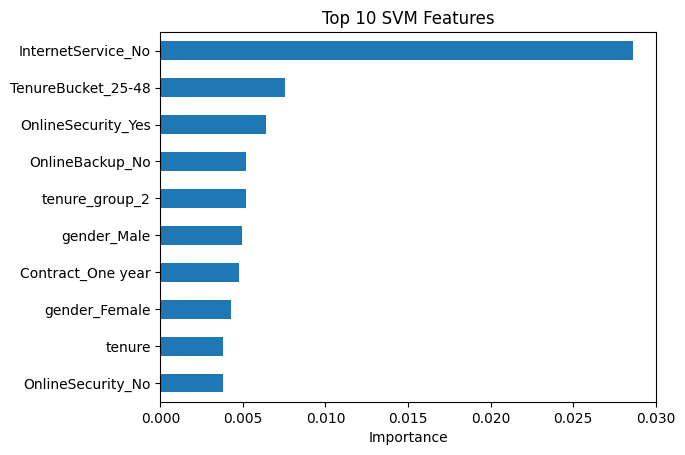

In [85]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

svm = SVC(kernel="rbf", probability=True, random_state=42)
svm.fit(X_train, y_train)

result = permutation_importance(svm, X_test, y_test, n_repeats=3, random_state=42)

importance = pd.Series(result.importances_mean, index=X_test.columns)
importance.nlargest(10).sort_values().plot(kind="barh")

plt.title("Top 10 SVM Features")
plt.xlabel("Importance")
plt.show()

## Step 8: Pipeline, Deployment & GitHub Submission

### 8.1  Save the Final Pipeline

In [86]:
import joblib
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

pipeline = Pipeline([
    ("model", DecisionTreeClassifier(
        max_depth=best_depth,
        class_weight="balanced",
        random_state=42
    ))
])

pipeline.fit(X_train, y_train)

joblib.dump(pipeline, "churn_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [87]:
import joblib

pipeline = joblib.load("churn_model.pkl")

sample = X_test.head(5)

prob = pipeline.predict_proba(sample)[:, 1]
pred = pipeline.predict(sample)

for i in range(5):
    print("Customer", i + 1)
    print("Churn Probability:", round(prob[i], 3))
    print("Prediction:", "Churn" if pred[i] == 1 else "No Churn")
    print()

Customer 1
Churn Probability: 0.0
Prediction: No Churn

Customer 2
Churn Probability: 0.571
Prediction: Churn

Customer 3
Churn Probability: 0.091
Prediction: No Churn

Customer 4
Churn Probability: 0.391
Prediction: No Churn

Customer 5
Churn Probability: 0.0
Prediction: No Churn

